# State Farm Distracted Driver Detection
## 1. Data Exploration

### Load metadata

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

csv_path = "../data/raw/state-farm-distracted-driver-detection/driver_imgs_list.csv"

df = pd.read_csv(csv_path)
df.head()


Matplotlib is building the font cache; this may take a moment.


,subject,classname,img
0,p002,c0,img_44733.jpg
1,p002,c0,img_72999.jpg
2,p002,c0,img_25094.jpg
3,p002,c0,img_69092.jpg
4,p002,c0,img_92629.jpg


In [4]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 22424 entries, 0 to 22423
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   subject    22424 non-null  str  
 1   classname  22424 non-null  str  
 2   img        22424 non-null  str  
dtypes: str(3)
memory usage: 525.7 KB
None


### Dataset size





In [5]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Unique drivers:", df["subject"].nunique())
print("Classes:", df["classname"].nunique())

Rows: 22424
Columns: 3
Unique drivers: 26
Classes: 10


## Class distribution


In [6]:
class_counts = df["classname"].value_counts().sort_index()
print(class_counts)

classname
c0    2489
c1    2267
c2    2317
c3    2346
c4    2326
c5    2312
c6    2325
c7    2002
c8    1911
c9    2129
Name: count, dtype: int64


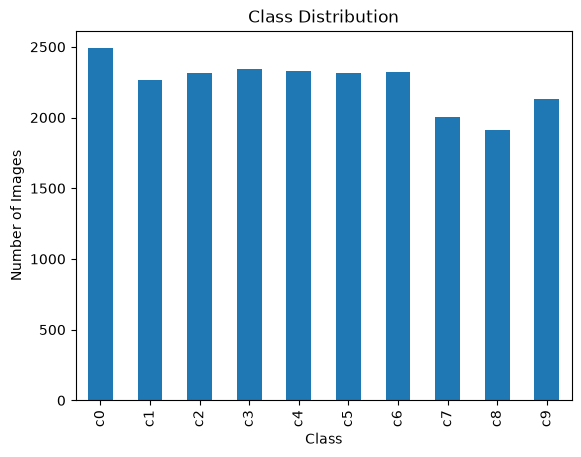

In [7]:
class_counts.plot(kind="bar")
plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.show()


## Driver distribution

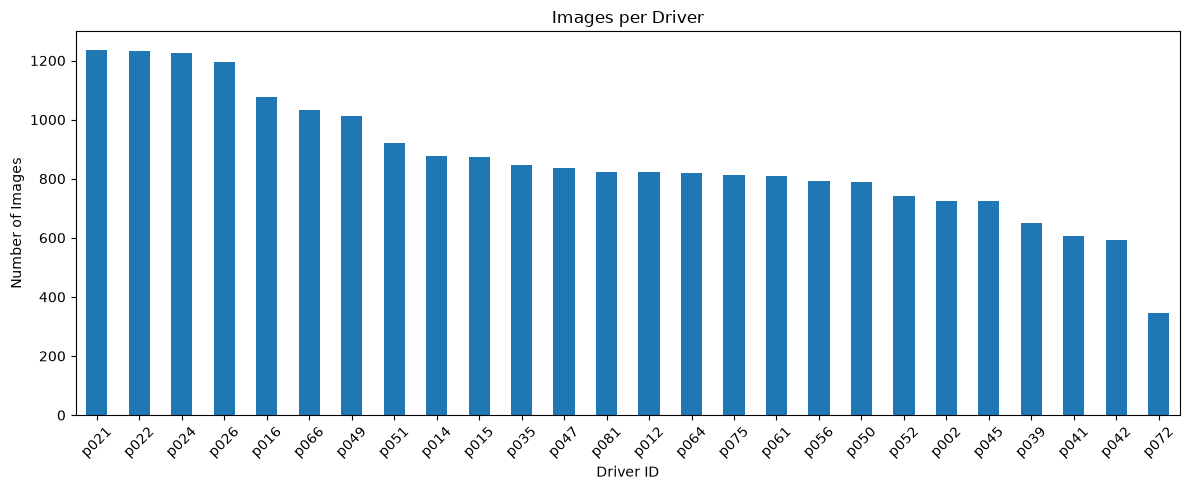

In [ ]:
driver_counts = df["subject"].value_counts().sort_values(ascending=False)
plt.figure(figsize=(12, 5))
driver_counts.plot(kind="bar")
plt.title("Images per Driver")
plt.xlabel("Driver ID")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## Sample images

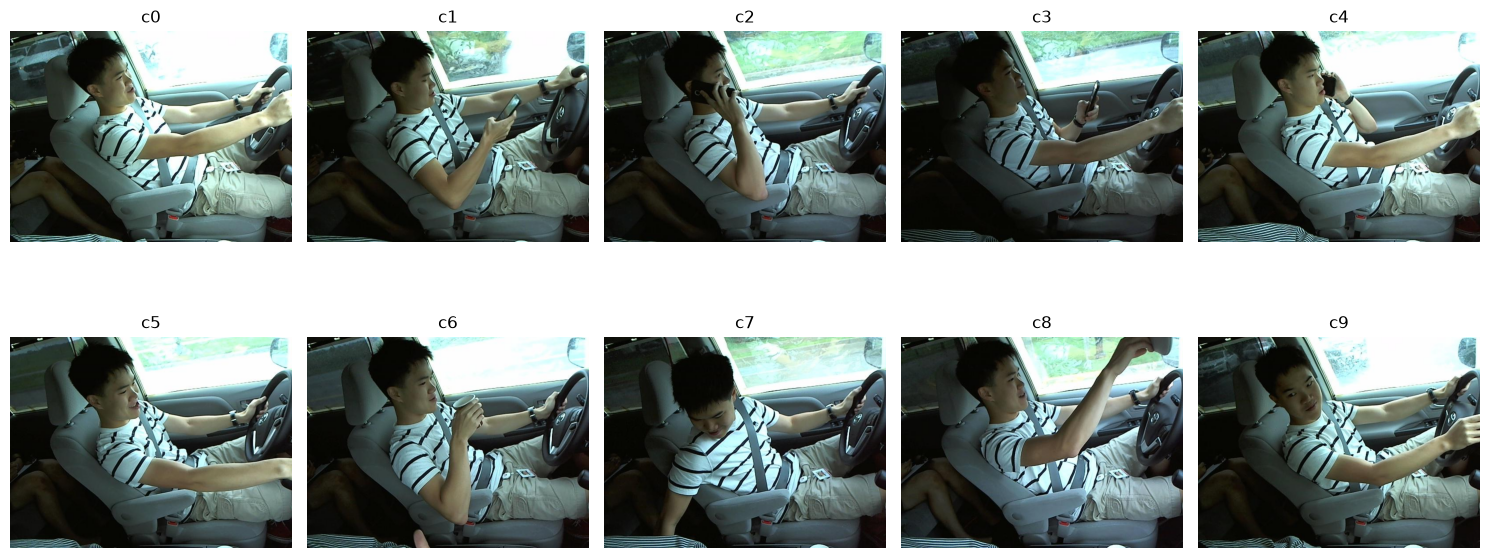

In [ ]:
import os
from PIL import Image

img_root = "../data/raw/state-farm-distracted-driver-detection/imgs/train" #root folder cotaining the images

classes = sorted(df["classname"].unique())

fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for ax, cls in zip(axes.flatten(), classes):
    sample_row = df[df["classname"] == cls].iloc[0]
    img_path = os.path.join(img_root, cls, sample_row["img"])

    img = Image.open(img_path)

    ax.imshow(img)
    ax.set_title(cls)
    ax.axis("off")

plt.tight_layout()
plt.show()

### Observation

The 10 classes represent different driver behaviors.  
Visually inspecting one example from each class helps us understand how similar some classes are.

For example:
- some classes involve holding a phone,
- some involve looking away from the road,
- some involve reaching or interacting with something inside the car.

These visual similarities may later explain some model misclassifications.

In [13]:
# Human-readable meaning of each class in the State Farm dataset.
class_names = {
    "c0": "Safe driving",
    "c1": "Texting - right",
    "c2": "Talking on phone - right",
    "c3": "Texting - left",
    "c4": "Talking on phone - left",
    "c5": "Operating the radio",
    "c6": "Drinking",
    "c7": "Reaching behind",
    "c8": "Hair and makeup",
    "c9": "Talking to passenger"
}

# Create a new column containing the readable behavior name.
df["behavior"] = df["classname"].map(class_names)

# Check the result.
df.head()

,subject,classname,img,behavior
0,p002,c0,img_44733.jpg,Safe driving
1,p002,c0,img_72999.jpg,Safe driving
2,p002,c0,img_25094.jpg,Safe driving
3,p002,c0,img_69092.jpg,Safe driving
4,p002,c0,img_92629.jpg,Safe driving


## Driver-Class Coverage

In [14]:
# Count how many images each driver has for each class.
driver_class_counts = pd.crosstab(
    df["subject"],
    df["classname"]
)

driver_class_counts

classname,c0,c1,c2,c3,c4,c5,c6,c7,c8,c9
subject,,,,,,,,,,
p002,76,74,86,79,84,76,83,72,44,51
p012,84,95,91,89,97,96,75,72,62,62
p014,100,103,100,100,103,102,101,77,38,52
p015,79,85,88,94,101,101,99,81,86,61
p016,111,102,101,128,104,104,108,101,99,120
p021,135,131,127,128,132,130,126,98,99,131
p022,129,129,128,129,130,130,131,98,98,131
p024,130,129,128,130,129,131,129,101,99,120
p026,130,129,130,131,126,130,128,97,97,98


In [15]:
# Count missing driver-class combinations.
missing_classes = (driver_class_counts == 0).sum().sum()

print("Missing driver-class combinations:", missing_classes)

Missing driver-class combinations: 0


## Initial observations